In [5]:
import os,random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
SEED = 42
random.seed(SEED);np.random.seed(SEED);tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)


TensorFlow 2.21.0 | Keras 3.15.1
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
TRAIN_DIR='/mnt/c/Users/sagni/EMO-Recognition/Datasets/train'
TEST_DIR='/mnt/c/Users/sagni/EMO-Recognition/Datasets/test'

In [7]:
class_names = sorted(os.listdir(TRAIN_DIR))
counts = pd.DataFrame({
    "train": [
        len(os.listdir(os.path.join(TRAIN_DIR, c)))
        for c in class_names
    ]
}, index=class_names)
NUM_CLASSES = len(class_names)
print(counts)

          train
angry      3995
disgust     436
fear       4097
happy      7215
neutral    4965
sad        4830
surprise   3171


In [8]:
BATCH = 64
VAL_SPLIT = 0.1
COLOR_MODE = "grayscale"
common = dict(labels="inferred",
              label_mode="categorical",
              color_mode=COLOR_MODE,image_size=(48, 48),
              batch_size=None)
raw_train = keras.utils.image_dataset_from_directory(TRAIN_DIR,
                                                     validation_split=VAL_SPLIT,
                                                     subset="training",
                                                     seed=SEED,
                                                     shuffle=True,
                                                     **common)
raw_val   = keras.utils.image_dataset_from_directory(TRAIN_DIR,
                                                     validation_split=VAL_SPLIT,
                                                     subset="validation",
                                                     seed=SEED,
                                                     shuffle=True,
                                                     **common)
raw_test  = keras.utils.image_dataset_from_directory(TEST_DIR,
                                                     shuffle=False,
                                                     **common)
assert raw_train.class_names == class_names

def prepare(ds, training):
    ds = ds.cache()
    if training:
        ds = ds.shuffle(5000, seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = prepare(raw_train, True), prepare(raw_val, False), prepare(raw_test, False)

# Class weights (square-root dampened "balanced" weights) to soften the imbalance without destabilising training
n = counts["train"].values
cw = (n.sum() / (NUM_CLASSES * n)) ** 0.5
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})

Found 28709 files belonging to 7 classes.
Using 25839 files for training.


I0000 00:00:1790866035.584689    1746 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5560 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
Class weights: {'angry': 1.01, 'disgust': 3.07, 'fear': 1.0, 'happy': 0.75, 'neutral': 0.91, 'sad': 0.92, 'surprise': 1.14}


In [9]:
def augmentation(value_range):
    """Random flip / rotation / zoom / brightness. Only active during training."""
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),                       # about +/- 15 degrees
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.15, value_range=value_range),
    ], name="augmentation")

def conv_block(x, filters, drop):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_custom_cnn():
    inp = keras.Input((48, 48, 1), name="face_gray")
    x = layers.Rescaling(1 / 255.0)(inp)
    x = augmentation((0, 1))(x)
    for f, d in [(32, 0.25), (64, 0.25), (128, 0.30), (256, 0.30)]:
        x = conv_block(x, f, d)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="emotion")(x)
    return keras.Model(inp, out, name="custom_cnn")

model = build_custom_cnn()
model.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ face_gray (InputLayer)          │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,242,919 (4.74 MB)

 Trainable params: 1,240,487 (4.73 MB)

 Non-trainable params: 2,432 (9.50 KB)

In [10]:
# Callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=80,
    class_weight=class_weight,
    callbacks=callbacks
)

Epoch 1/80


/home/sagnik/miniconda3/envs/tf-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1790866074.599366    1746 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/custom_cnn_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1790866083.002687    1833 cuda_dnn.cc:461] Loaded cuDNN version 92700


404/404 ━━━━━━━━━━━━━━━━━━━━ 50s 90ms/step - accuracy: 0.2168 - loss: 1.9756 - val_accuracy: 0.2557 - val_loss: 2.0225 - learning_rate: 0.0010
Epoch 2/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.3415 - loss: 1.6847 - val_accuracy: 0.4024 - val_loss: 1.6532 - learning_rate: 0.0010
Epoch 3/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.4347 - loss: 1.4620 - val_accuracy: 0.4547 - val_loss: 1.4584 - learning_rate: 0.0010
Epoch 4/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.4767 - loss: 1.3622 - val_accuracy: 0.4310 - val_loss: 1.5256 - learning_rate: 0.0010
Epoch 5/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.5002 - loss: 1.3078 - val_accuracy: 0.4557 - val_loss: 1.4415 - learning_rate: 0.0010
Epoch 6/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.5140 - loss: 1.2663 - val_accuracy: 0.5328 - val_loss: 1.2119 - learning_rate: 0.0010
Epoch 7/80
404/404 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - accuracy: 0.5281 - loss: 1.2307

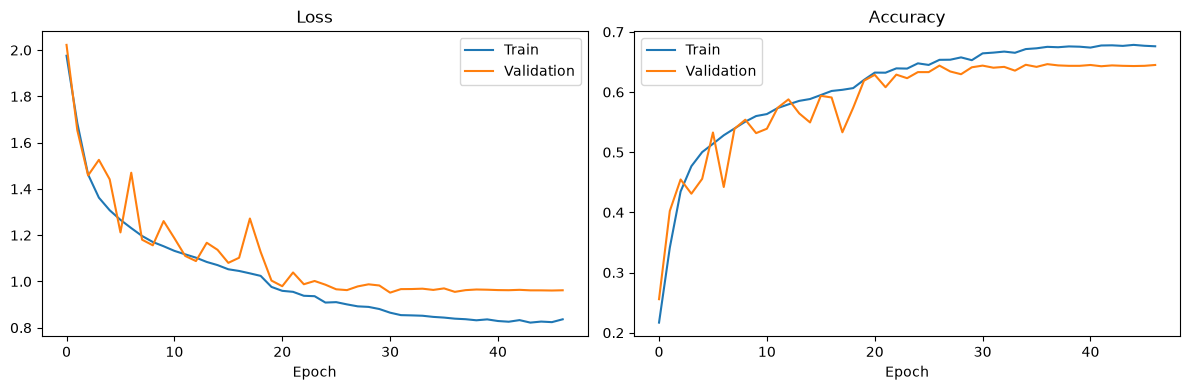

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
model.save("/mnt/c/Users/sagni/EMO-Recognition/Models/custom_cnn.keras")

In [14]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

113/113 ━━━━━━━━━━━━━━━━━━━━ 17s 152ms/step - accuracy: 0.6507 - loss: 0.9416
Test Loss: 0.9415919184684753
Test Accuracy: 0.6507383584976196


In [15]:
y_true = np.concatenate([
    y.numpy().argmax(axis=1)
    for _, y in test_ds
])

y_pred = model.predict(test_ds).argmax(axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step 
              precision    recall  f1-score   support

       angry       0.55      0.59      0.57       958
     disgust       0.49      0.68      0.57       111
        fear       0.53      0.38      0.44      1024
       happy       0.87      0.85      0.86      1774
     neutral       0.57      0.68      0.62      1233
         sad       0.56      0.48      0.52      1247
    surprise       0.72      0.82      0.77       831

    accuracy                           0.65      7178
   macro avg       0.61      0.64      0.62      7178
weighted avg       0.65      0.65      0.65      7178



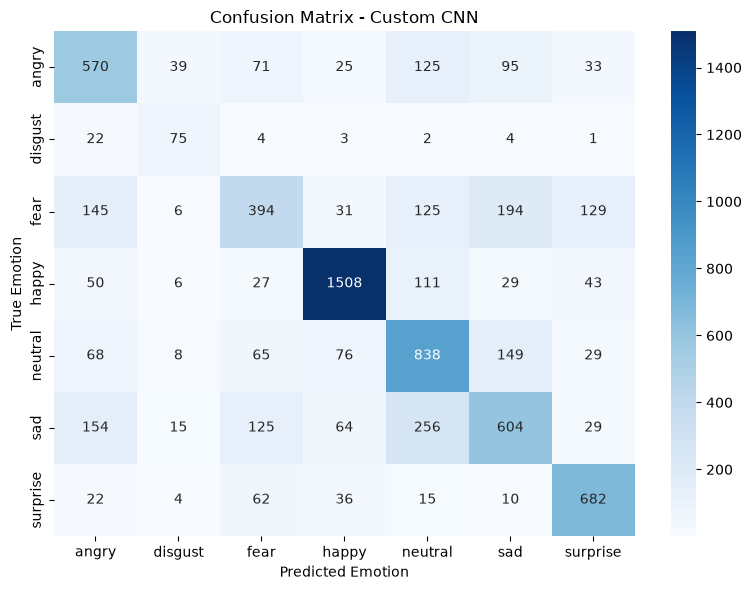

In [16]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.title("Confusion Matrix - Custom CNN")
plt.tight_layout()
plt.show()